
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 4</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



# <font color = lightGreen> PART 4:
 </font>

In [1]:
!pip install stable-baselines3


Defaulting to user installation because normal site-packages is not writeable


In [2]:
from stable_baselines3 import A2C
from stable_baselines3.common.env_util import make_vec_env
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [3]:
env_id = "CartPole-v1"
env = make_vec_env(env_id, n_envs=1)

a2c_params = {
    "policy": "MlpPolicy",
    "env": env,
    "learning_rate": 1e-4,
    "n_steps": 5,
    "gamma": 0.99,
    "gae_lambda": 1.0,
    "ent_coef": 0.0,
    "vf_coef": 0.5,
    "max_grad_norm": 0.5,
    "use_rms_prop": True,
    "normalize_advantage": True,
    "tensorboard_log": "./a2c_cartpole_tensorboard/"
}

model = A2C(**a2c_params)
reward_log = []


In [6]:
class RewardCallback:
    def __init__(self):
        self.rewards = []

    def __call__(self, locals_, globals_):
        if "infos" in locals_:
            for info in locals_["infos"]:
                if "episode" in info.keys():
                    self.rewards.append(info["episode"]["r"])
        return True

reward_callback = RewardCallback()


In [7]:
timesteps = 20000
model.learn(total_timesteps=timesteps, callback=reward_callback)

rewards = np.array(reward_callback.rewards)
reward_means = [np.mean(rewards[max(0, i - 100):i]) for i in range(1, len(rewards) + 1)]
reward_stds = [np.std(rewards[max(0, i - 100):i]) for i in range(1, len(rewards) + 1)]
x_vals = range(1, len(reward_means) + 1)
lower_bound = [mean - 1.96 * std for mean, std in zip(reward_means, reward_stds)]
upper_bound = [mean + 1.96 * std for mean, std in zip(reward_means, reward_stds)]


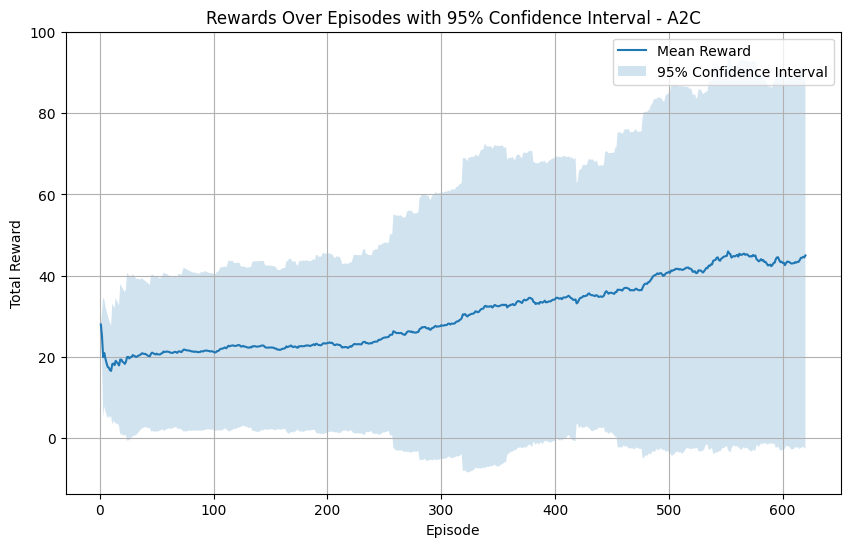

In [10]:

plt.figure(figsize=(10, 6))
plt.plot(x_vals, reward_means, label="Mean Reward")
plt.fill_between(x_vals, lower_bound, upper_bound, alpha=0.2, label="95% Confidence Interval")
plt.title("Rewards Over Episodes with 95% Confidence Interval - A2C")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.legend()
plt.grid()
plt.show()
